<a href="https://colab.research.google.com/github/MNMARQUES/MachineLearning/blob/main/EML_Projeto1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier


In [2]:

uploaded = files.upload()

arquivo = next(iter(uploaded))

df = pd.read_csv(arquivo, sep=';')

print("Dimensões do dataset:", df.shape)
display(df.head())


Saving winequality-red.csv to winequality-red.csv
Dimensões do dataset: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


Valores ausentes por coluna:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
Registros duplicados: 240

Distribuição da qualidade:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


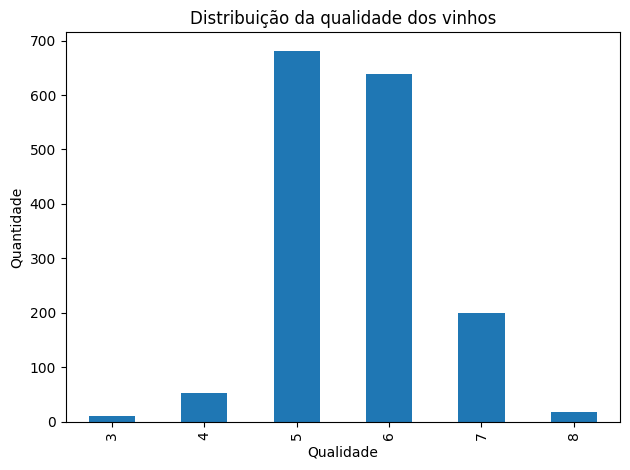

In [3]:

# Tipos de dados e informações gerais
df.info()

# Estatísticas descritivas
display(df.describe())

# Verificar valores ausentes
print("Valores ausentes por coluna:")
print(df.isnull().sum())

# Verificar registros duplicados
print("Registros duplicados:", df.duplicated().sum())

# Distribuição da variável quality
print("\nDistribuição da qualidade:")
print(df["quality"].value_counts().sort_index())

df["quality"].value_counts().sort_index().plot(
    kind="bar",
    title="Distribuição da qualidade dos vinhos",
    xlabel="Qualidade",
    ylabel="Quantidade"
)

plt.tight_layout()
plt.show()


In [4]:

# Variáveis de entrada
X = df.drop(columns=["quality"])

# Variável de saída
y = df["quality"]

# Divisão: 70% treinamento e 30% teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=1
)

# Normalização das entradas
scaler = MinMaxScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Treinamento:", X_train_scaled.shape)
print("Teste:", X_test_scaled.shape)


Treinamento: (1119, 11)
Teste: (480, 11)


In [5]:

modelos = {
    "KNN": KNeighborsClassifier(n_neighbors=5),

    "Árvore de Decisão": DecisionTreeClassifier(),

    "Floresta Randômica": RandomForestClassifier(
        max_depth=10,
        random_state=1
    ),

    "SVM": SVC(
        gamma="auto",
        kernel="rbf"
    ),

    "Rede MLP": MLPClassifier(
        alpha=1e-5,
        hidden_layer_sizes=(5, 5),
        random_state=1
    )
}

resultados = []

for nome, modelo in modelos.items():
    modelo.fit(X_train_scaled, y_train)

    previsoes = modelo.predict(X_test_scaled)

    acuracia = accuracy_score(y_test, previsoes)

    resultados.append({
        "Algoritmo": nome,
        "Acurácia": acuracia
    })

    print(f"\n{'=' * 50}")
    print(nome)
    print(f"Acurácia: {acuracia:.4f}")
    print(classification_report(
        y_test,
        previsoes,
        zero_division=0
    ))



KNN
Acurácia: 0.5583
              precision    recall  f1-score   support

           3       1.00      0.50      0.67         2
           4       0.33      0.05      0.08        21
           5       0.61      0.71      0.65       207
           6       0.54      0.52      0.53       195
           7       0.38      0.35      0.36        52
           8       0.00      0.00      0.00         3

    accuracy                           0.56       480
   macro avg       0.48      0.35      0.38       480
weighted avg       0.54      0.56      0.54       480


Árvore de Decisão
Acurácia: 0.6062
              precision    recall  f1-score   support

           3       0.00      0.00      0.00         2
           4       0.19      0.14      0.16        21
           5       0.68      0.71      0.70       207
           6       0.63      0.57      0.60       195
           7       0.45      0.56      0.50        52
           8       0.17      0.33      0.22         3

    accuracy       

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


,Algoritmo,Acurácia
0,Floresta Randômica,0.677083
1,Árvore de Decisão,0.606250
2,Rede MLP,0.597917
3,SVM,0.583333
4,KNN,0.558333


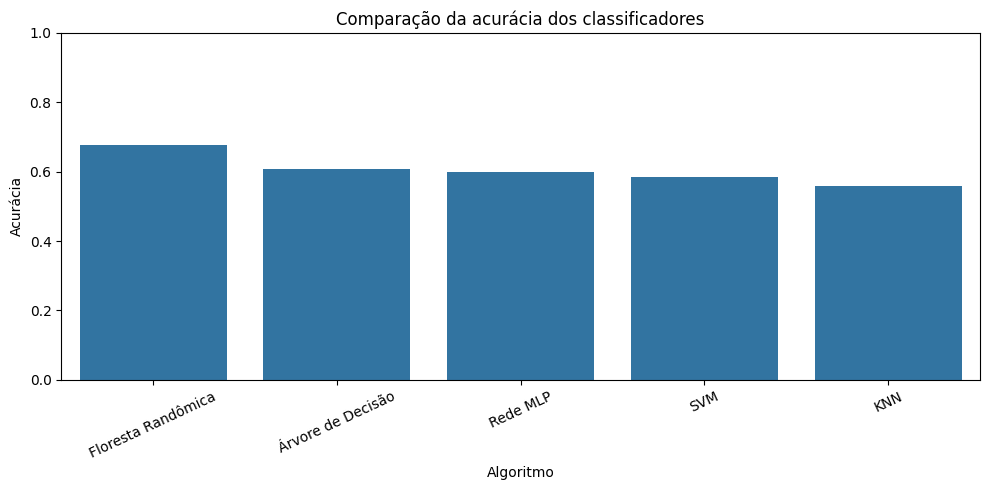

Melhor modelo pela acurácia: Floresta Randômica


In [6]:

df_resultados = pd.DataFrame(resultados)

df_resultados = df_resultados.sort_values(
    by="Acurácia",
    ascending=False
).reset_index(drop=True)

display(df_resultados)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_resultados,
    x="Algoritmo",
    y="Acurácia"
)

plt.title("Comparação da acurácia dos classificadores")
plt.ylim(0, 1)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

print(
    "Melhor modelo pela acurácia:",
    df_resultados.iloc[0]["Algoritmo"]
)


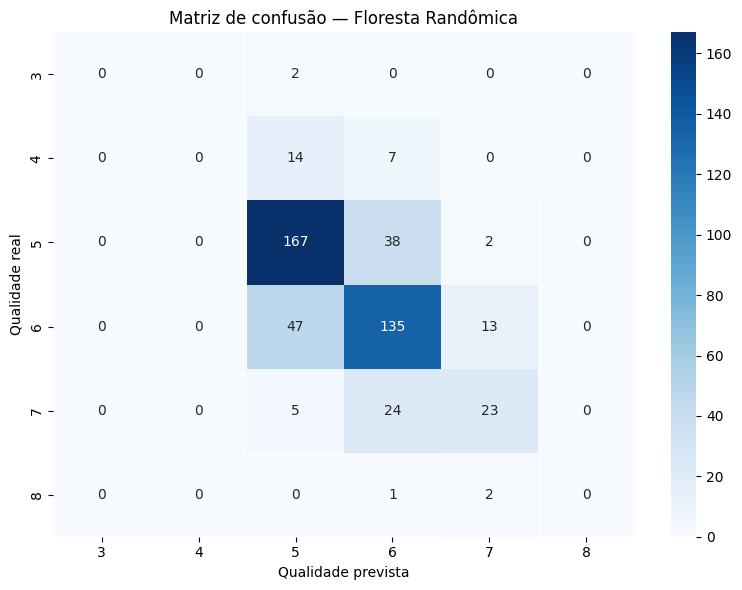

In [7]:

melhor_nome = df_resultados.iloc[0]["Algoritmo"]
melhor_modelo = modelos[melhor_nome]

y_pred = melhor_modelo.predict(X_test_scaled)

matriz = confusion_matrix(
    y_test,
    y_pred,
    labels=melhor_modelo.classes_
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=melhor_modelo.classes_,
    yticklabels=melhor_modelo.classes_
)

plt.xlabel("Qualidade prevista")
plt.ylabel("Qualidade real")
plt.title(f"Matriz de confusão — {melhor_nome}")
plt.tight_layout()
plt.show()
